In [1]:
# Import all required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import os
import platform
import datetime as dt

In [2]:
os.makedirs('data', exist_ok=True)
print("python", platform.python_version())
print("pandas", pd.__version__)
print("numpy", np.__version__)
print("yfinance", yf.__version__)

python 3.13.18
pandas 2.2.3
numpy 2.4.6
yfinance 0.2.66


In [3]:
# Part 1: Extract S&P 500 tickers from Wikipedia using Pandas
# User-Agent is required to avoid HTTP 403 blocking from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

retrieval_date = dt.datetime.now(dt.timezone.utc).strftime('%Y-%m-%d %H:%M UTC')
sp500_df['Ticker'] = tickers
sp500_df['Retrieval_Date'] = retrieval_date
sp500_df.to_csv('data/SP500_tickers.csv', index=False)
print('Retrieved:', retrieval_date)

print('Total tickers extracted:', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Retrieved: 2026-11-22 00:42 UTC
Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [4]:
#Part2: Load Daily Market Data via yfinance
# Download daily closing prices for all S&P 500 tickers
# Period: 01-01-2021 to 01-01-2025 | Close price (adjusted)
start = '2021-01-01'
end = '2025-01-01'

data = yf.download(tickers, start=start, end=end, auto_adjust=False, actions = True)
df = data['Adj Close']
close = data['Close']
volume = data['Volume']

df.to_csv('data/SP500_prices.csv')
close.to_csv('data/SP500_close.csv')
volume.to_csv('data/SP500_volume.csv')
print('Shape:', df.shape)
df.head()



[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'VYLR', 'SNDK', 'Q', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Shape: (1005, 503)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009125,125.537109,84.219147,139.149994,97.269699,33.186359,232.029312,485.339996,132.622635,42.189484,...,26.124489,102.852104,54.757374,33.042759,93.015892,221.160004,95.016182,141.603348,378.130005,152.951996
2021-01-05,114.941261,127.089203,85.089996,148.300003,98.473206,33.319485,233.350296,485.690002,134.993149,43.010101,...,26.371326,106.017509,54.223656,34.635185,92.903923,229.750000,95.025146,144.053406,380.570007,154.017899
2021-01-06,118.093224,122.811211,84.354965,142.770004,98.268173,34.783871,235.901627,466.309998,135.601685,44.752834,...,26.506687,106.652527,55.424545,35.518974,96.822723,226.889999,95.545967,148.158356,394.820007,156.280533
2021-01-07,121.235603,127.001938,85.257797,151.270004,99.222069,34.460564,238.127319,477.739990,141.332733,44.355221,...,26.761480,105.594185,54.340397,35.797657,101.217415,239.479996,94.818634,147.280029,409.100006,156.140259
2021-01-08,122.100471,128.098099,85.705200,149.770004,99.498390,34.650742,238.995819,485.100006,142.359039,44.473660,...,26.578346,104.901451,54.840782,36.195759,100.191071,241.449997,96.210396,146.956467,405.470001,157.178085


In [5]:
print('Duplicate dates:', df.index.duplicated().sum())
print('Non-positive prices:', list(df.columns[((df <= 0) | (close <= 0)).any()]))
print('Non-positive volumes:', list(df.columns[((volume <= 0)).any()]))
print('Zero volume days:', list(df.columns[((volume == 0) & close.notna()).any()]))

if 'Stock Splits' in data.columns.get_level_values(0):
  splits = data['Stock Splits'].fillna(0)
  splits_check = [(d.date(), t, splits.at[d, t], close[t].pct_change(fill_method=None).at[d])
        for t in splits.columns
        for d in splits.index[splits[t] > 0]]
  print(pd.DataFrame(splits_check, columns=['Date','Share','Ratio','Close_return_on_day']))

Duplicate dates: 0
Non-positive prices: []
Non-positive volumes: ['FERG', 'SW']
Zero volume days: ['FERG', 'SW']
          Date Share  Ratio  Close_return_on_day
0   2022-06-06  AMZN  20.00             0.019943
1   2021-11-18  ANET   4.00             0.003558
2   2024-12-04  ANET   4.00             0.017517
3   2021-03-05   APH   2.00             0.025316
4   2024-06-12   APH   2.00             0.021945
..         ...   ...    ...                  ...
56  2024-02-26   WMT   3.00             0.018455
57  2022-03-24   WRB   1.50             0.000613
58  2024-07-11   WRB   1.50            -0.015007
59  2024-07-09   WSM   2.00            -0.002595
60  2022-03-01   ZBH   1.03             0.005301

[61 rows x 4 columns]


In [6]:
# Transpose DataFrame: rows = tickers, columns = dates
df1 = df.T

print('Shape after transpose:', df1.shape)
df1


Shape after transpose: (503, 1005)


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
A,114.009125,114.941261,118.093224,121.235603,122.100471,123.147919,122.013954,122.023582,121.110664,121.283646,...,134.353806,130.957047,131.134277,132.433899,132.522491,133.999344,133.733521,133.447983,132.345245,132.510986
AAPL,125.537109,127.089203,122.811211,127.001938,128.098099,125.119957,124.945366,126.972832,125.052101,123.335045,...,251.462662,246.075912,247.802032,252.464645,253.238434,256.145111,256.958557,253.555878,250.192841,248.427017
ABBV,84.219147,85.089996,84.354965,85.257797,85.705200,87.103424,87.710617,89.843857,90.231857,89.334625,...,164.530716,162.316696,160.909485,164.718338,167.354492,168.864883,168.114395,166.998016,165.299973,166.707184
ABNB,139.149994,148.300003,142.770004,151.270004,149.770004,148.130005,160.800003,169.990005,180.500000,169.270004,...,132.240005,127.540001,129.350006,134.210007,134.520004,134.990005,135.320007,133.384995,131.809998,131.410004
ABT,97.269699,98.473206,98.268173,99.222069,99.498390,98.811958,97.028999,99.979797,98.493980,99.621780,...,108.486847,107.184517,107.653732,109.387001,109.463600,109.894524,110.382904,110.114784,108.017624,108.314484
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYZ,221.160004,229.750000,226.889999,239.479996,241.449997,225.500000,227.520004,230.919998,232.789993,227.750000,...,94.550003,87.300003,87.639999,89.650002,89.290001,91.080002,91.480003,88.970001,87.480003,84.989998
YUM,95.016182,95.025146,95.545967,94.818634,96.210396,96.677299,96.677299,96.210396,96.776093,95.734535,...,130.267365,127.105698,126.042145,127.975876,129.426224,130.528442,131.495316,130.750824,129.097473,129.716263
ZBH,141.603348,144.053406,148.158356,147.280029,146.956467,147.002716,147.770065,150.654648,150.349579,148.038208,...,105.912384,103.756111,103.707108,104.991066,104.697021,105.167488,105.118484,104.746033,103.537781,103.763710


In [7]:
# Part 3: Identify and Remove Invalid Data
# 1. Drop tickers (rows) that are entirely NaN
# 2. Drop tickers with less than 80% of dates available
# 3. Forward-fill then back-fill remaining gaps
# 4. Drop any remaining fully NaN rows
print('Before cleaning:', df1.shape)

df1 = df1.dropna(how='all')

bad = (df1.isna().any(axis=1)
        | close.T.reindex(df1.index).isna().any(axis = 1)
        | volume.T.reindex(df1.index).isna().any(axis = 1)
        | (df1 <= 0).any(axis = 1)
        | (volume.T.reindex(df1.index) < 0).any(axis = 1))


df1 = df1[~bad]

excluded = sorted(set(tickers) - set(df1.index))
exclusion_log = pd.DataFrame({'Share': excluded,
                              'First_date': [df[t].first_valid_index() if t in df else None for t in excluded],
                              'Missing_days': [int(df[t].isna().sum()) if t in df else None for t in excluded]})
exclusion_log.to_csv('data/exclusion_log.csv', index=False)

print('After cleaning:', df1.shape)
print('Rows (tickers) removed:', 503 - df1.shape[0])
df1.head()

Before cleaning: (503, 1005)
After cleaning: (488, 1005)
Rows (tickers) removed: 15


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
A,114.009125,114.941261,118.093224,121.235603,122.100471,123.147919,122.013954,122.023582,121.110664,121.283646,...,134.353806,130.957047,131.134277,132.433899,132.522491,133.999344,133.733521,133.447983,132.345245,132.510986
AAPL,125.537109,127.089203,122.811211,127.001938,128.098099,125.119957,124.945366,126.972832,125.052101,123.335045,...,251.462662,246.075912,247.802032,252.464645,253.238434,256.145111,256.958557,253.555878,250.192841,248.427017
ABBV,84.219147,85.089996,84.354965,85.257797,85.705200,87.103424,87.710617,89.843857,90.231857,89.334625,...,164.530716,162.316696,160.909485,164.718338,167.354492,168.864883,168.114395,166.998016,165.299973,166.707184
ABNB,139.149994,148.300003,142.770004,151.270004,149.770004,148.130005,160.800003,169.990005,180.500000,169.270004,...,132.240005,127.540001,129.350006,134.210007,134.520004,134.990005,135.320007,133.384995,131.809998,131.410004
ABT,97.269699,98.473206,98.268173,99.222069,99.498390,98.811958,97.028999,99.979797,98.493980,99.621780,...,108.486847,107.184517,107.653732,109.387001,109.463600,109.894524,110.382904,110.114784,108.017624,108.314484


In [8]:
import pandas as pd

def calculate_weekly_returns(df1, shares=None):
    """Calculate weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]

    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample("W-FRI").last()
    weekly_prices = weekly_prices[(weekly_prices.index - pd.Timedelta(days=6) >= start) & (weekly_prices.index < end)]
    return weekly_prices.pct_change(fill_method=None)

In [9]:
# All shares weekly returns
weekly_returns = calculate_weekly_returns(df1).iloc[1:]

In [10]:
weekly_returns


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.006690,-0.037183,0.042348,0.130200,0.001240,-0.048024,-0.036505,-0.055700,0.006444,-0.007038,...,-0.025764,-0.025681,-0.012165,0.053454,-0.036134,-0.056741,-0.004946,0.007361,0.009249,-0.038962
2021-01-22,0.000951,0.093834,0.003076,0.074437,0.013836,-0.039781,0.004416,0.031348,-0.013756,0.011878,...,0.021218,0.011484,-0.003079,-0.009605,-0.008696,-0.021383,0.004408,0.005558,-0.000929,0.012522
2021-01-29,-0.048761,-0.051125,-0.075591,0.009677,0.095268,-0.057040,-0.050438,-0.028935,-0.053027,-0.053200,...,-0.060825,-0.073709,-0.011890,-0.054607,-0.058577,-0.031048,-0.052293,-0.045587,-0.051389,-0.055593
2021-02-05,0.025048,0.037923,0.060987,0.063606,0.003560,0.076090,0.048032,0.072694,0.009706,0.065787,...,0.102918,0.175425,-0.008595,0.113961,0.016565,0.113076,0.037935,0.040477,0.049713,0.032609
2021-02-12,0.038967,-0.010164,-0.039455,0.088936,0.033863,0.039941,0.015501,0.013655,0.080801,0.052711,...,0.018604,0.007351,-0.029949,0.028588,0.009472,0.134662,0.006033,0.009319,0.173491,0.046648
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-29,0.030858,0.032453,0.033795,-0.008956,0.008577,0.010332,0.010344,0.007381,0.016124,0.027668,...,0.039074,0.033848,0.016959,-0.031447,0.001851,-0.040212,0.027131,0.017057,0.024699,-0.009663
2024-12-06,0.018917,0.023217,-0.036845,0.005951,-0.026690,-0.028693,0.000911,0.071773,0.000688,-0.058242,...,-0.030068,-0.000106,-0.038864,-0.037216,-0.002998,0.109543,-0.004629,-0.036307,0.005700,0.006904
2024-12-13,-0.011239,0.021784,-0.016006,-0.043602,-0.019204,-0.045078,-0.011084,-0.157823,-0.003084,0.019059,...,-0.039310,0.001695,-0.023229,-0.024038,-0.045660,-0.063817,-0.004577,-0.011941,-0.013999,0.009747


In [11]:
mean_weekly_return = weekly_returns.mean().rename('Mean_Weekly_Return')
print('Weekly observations:', len(weekly_returns))
print('Mean weekly return:', mean_weekly_return)
print(mean_weekly_return.describe())

Weekly observations: 207
Mean weekly return: Ticker
A       0.001121
AAPL    0.003930
ABBV    0.003749
ABNB    0.001475
ABT     0.000971
          ...   
XYZ    -0.001554
YUM     0.001807
ZBH    -0.001105
ZBRA    0.001181
ZTS     0.000763
Name: Mean_Weekly_Return, Length: 488, dtype: float64
count    488.000000
mean       0.002857
std        0.002646
min       -0.004468
25%        0.001182
50%        0.002629
75%        0.004207
max        0.017772
Name: Mean_Weekly_Return, dtype: float64


In [12]:
import pandas as pd
import numpy as np

def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [13]:
# Pass market_weekly_returns as a Series by selecting its column
market_prices = yf.download("^GSPC", start=start, end=end, auto_adjust=False)["Adj Close"]
market_weekly_returns = calculate_weekly_returns(market_prices.T).iloc[1:]
market_weekly_returns = pd.DataFrame({"^GSPC": market_weekly_returns.squeeze()})

beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns["^GSPC"],
    min_weeks = len(market_weekly_returns)
)
print('Aligned weekly observations per beta:', beta_df['Paired_weeks'].unique())
print('Shares with missing beta:', int(beta_df['Beta'].isna().sum()))
beta_df.head()

[*********************100%***********************]  1 of 1 completed


Aligned weekly observations per beta: [207]
Shares with missing beta: 0


,Beta,Paired_weeks
Share,,
A,1.074724,207
AAPL,1.174836,207
ABBV,0.425365,207
ABNB,1.472709,207
ABT,0.583543,207


In [14]:
# Combine into one DataFrame
combined_df = (
    weekly_returns
    .rename_axis(index="Week", columns="Share")
    .reset_index()
    .melt(
        id_vars="Week",
        var_name="Share",
        value_name="Weekly_Return"
    )
    .join(beta_df[["Beta"]], on="Share")
    .sort_values(["Share", "Week"])
    .reset_index(drop=True)
)

combined_df

,Week,Share,Weekly_Return,Beta
0,2021-01-15,A,-0.006690,1.074724
1,2021-01-22,A,0.000951,1.074724
2,2021-01-29,A,-0.048761,1.074724
3,2021-02-05,A,0.025048,1.074724
4,2021-02-12,A,0.038967,1.074724
...,...,...,...,...
101011,2024-11-29,ZTS,-0.009663,0.979783
101012,2024-12-06,ZTS,0.006904,0.979783
101013,2024-12-13,ZTS,0.009747,0.979783
101014,2024-12-20,ZTS,-0.074868,0.979783


In [15]:
# Count null values in each column
print("Null values per column:")
print(combined_df.isna().sum())

# Remove rows with any null values
rows_before = len(combined_df)
combined_df = combined_df.dropna().reset_index(drop=True)

print("Rows removed:", rows_before - len(combined_df))
print("Rows remaining:", len(combined_df))

Null values per column:
Week             0
Share            0
Weekly_Return    0
Beta             0
dtype: int64
Rows removed: 0
Rows remaining: 101016


#Part 4: Stock-market RFM
R = number of calendar days between most recent high volume day and date of observation (smaller = more recent, absent = missing, not 0). F = number of high-volume days in the last 60 trading days. M = sum of Close multiplied by Volume for last 60 trading days in USD (approx. dollar value traded, not market capitalisation) A transaction is defined as high volume if the volume is more than twice the average volume of the 20 days prior (excluding the day in question). Date of observation is the most recent completed trading day on which all data is common. These are not conventional customer RFM values but rather are defined for use in this research.

In [16]:
import numpy as np
import pandas as pd

vol = volume[df1.index].replace([np.inf, -np.inf], np.nan).sort_index()
vol = vol.loc[(vol.index >= '2021-01-01') & (vol.index < '2025-01-01')]
vol = vol.dropna(axis=1, how='all')
cls = close[vol.columns].loc[vol.index]

snapshot = vol.dropna().index.max()
vol, cls = vol.loc[:snapshot], cls.loc[:snapshot]

average_volume = vol.shift(1).rolling(20).mean()
high_volume = (vol > 2 * average_volume) & average_volume.notna()

recency = pd.Series({
    ticker: (snapshot - high_volume.index[np.flatnonzero(high_volume[ticker].to_numpy())[-1]]).days
            if high_volume[ticker].any() else np.nan
    for ticker in vol.columns
}, name='Recency')

last60 = vol.index[-60:]
frequency = high_volume.loc[last60].sum(axis=0).rename('Frequency')
valid_days = average_volume.notna().sum(axis=0).rename('Valid_Days')
monetary = (cls.loc[last60] * vol.loc[last60]).sum(axis=0).rename('Monetary')

rfm = pd.concat([recency, frequency, valid_days, monetary], axis=1)
print('Shares with fewer than 60 valid days:', int((rfm['Valid_Days'] < 60).sum()))

def score_five(series, ascending_better=True):
    percentile = series.rank(pct=True, method='average', ascending=ascending_better)
    return np.ceil(percentile * 5).clip(1, 5).astype('Int64')

rfm['R_Score'] = score_five(rfm['Recency'], ascending_better=False)
rfm['F_Score'] = score_five(rfm['Frequency'], ascending_better=True)
rfm['M_Score'] = score_five(rfm['Monetary'], ascending_better=True)
rfm['RFM_Score'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)
rfm['RFM_Code'] = (rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str))
rfm = rfm.sort_values(['RFM_Score', 'Monetary', 'Frequency'], ascending=[False, False, False])
rfm['Rank'] = np.arange(1, len(rfm) + 1)
rfm.index.name = 'Share'
rfm = rfm.reset_index()

obs_date = snapshot
shares = rfm['Share'].tolist()

print('Snapshot:', snapshot.date())
print('Shares ranked:', len(rfm))
print('No high-volume event (R missing):', int(rfm['Recency'].isna().sum()))
print(rfm.head(20).to_string(index=False))


Shares with fewer than 60 valid days: 0
Snapshot: 2024-12-31
Shares ranked: 488
No high-volume event (R missing): 0
Share  Recency  Frequency  Valid_Days     Monetary  R_Score  F_Score  M_Score  RFM_Score RFM_Code  Rank
 AMZN       11          5         985 4.681770e+11        4        5        5         14      455     1
 AVGO       11          6         985 3.340388e+11        4        5        5         14      455     2
 PLTR       11          6         985 2.869115e+11        4        5        5         14      455     3
 GOOG       11          5         985 2.028245e+11        4        5        5         14      455     4
   BA       11          5         985 1.276863e+11        4        5        5         14      455     5
  MCD       11          5         985 6.310161e+10        4        5        5         14      455     6
 WDAY       11          5         985 5.170406e+10        4        5        5         14      455     7
  AJG        4          6         985 2.824304e+10  

In [17]:
ex_t = 'AAPL' if 'AAPL' in shares else shares[0]
ex = pd.DataFrame({"Close": close[ex_t], "Volume": volume[ex_t]}).loc[:obs_date]
ex["Avg20_prev"] = ex["Volume"].shift(1).rolling(20).mean()
ex["Threshold"] = 2 * ex["Avg20_prev"]
ex["HighVolume"] = ex["Volume"] > ex["Threshold"]
ex["Close_x_Volume"] = ex["Close"] * ex["Volume"]
last60 = ex.tail(60)
row = rfm.set_index("Share").loc[ex_t]

print(ex_t, '| observation date', obs_date.date())
print('High-volume days in last 60 sessions:', list(last60.index[last60["HighVolume"]].date))
print('R =', row.Recency, 'calendar days | F =', row.Frequency, '| M = $', f"{row.Monetary:,.0f}")
last60[last60["HighVolume"]].round(2) if last60["HighVolume"].any() else last60.tail(5).round(2)

AAPL | observation date 2024-12-31
High-volume days in last 60 sessions: [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)]
R = 11 calendar days | F = 2 | M = $ 623,303,377,707


,Close,Volume,Avg20_prev,Threshold,HighVolume,Close_x_Volume
Date,,,,,,
2024-11-25,232.87,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.49,147495300,45004605.0,90009210.0,True,3.753608e+10


In [18]:
# Full RFM table and exports
from IPython.display import display

sectors = sp500_df.set_index('Ticker')['GICS Sector']
rfm = (rfm.set_index('Share')
          .join(mean_weekly_return)
          .join(beta_df[['Beta']])
          .join(sectors.rename('Sector'))
          .reset_index())

display(rfm)
display(rfm[['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary']].describe())
rfm.to_csv('SP500_RFM_2021_2024.csv', index=False)
rfm.to_excel('SP500_RFM_2021_2024.xlsx', index=False)
print('Saved SP500_RFM_2021_2024.csv and SP500_RFM_2021_2024.xlsx')

,Share,Recency,Frequency,Valid_Days,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Code,Rank,Mean_Weekly_Return,Beta,Sector
0,AMZN,11,5,985,4.681770e+11,4,5,5,14,455,1,0.002681,1.386667,Consumer Discretionary
1,AVGO,11,6,985,3.340388e+11,4,5,5,14,455,2,0.010133,1.515254,Information Technology
2,PLTR,11,6,985,2.869115e+11,4,5,5,14,455,3,0.009613,2.003194,Information Technology
3,GOOG,11,5,985,2.028245e+11,4,5,5,14,455,4,0.004629,1.209199,Communication Services
4,BA,11,5,985,1.276863e+11,4,5,5,14,455,5,0.000614,1.134751,Industrials
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
483,JKHY,46,2,985,6.090703e+09,1,2,1,4,121,484,0.000966,0.621046,Financials
484,LNT,60,2,985,5.708137e+09,1,2,1,4,121,485,0.001908,0.492376,Utilities
485,MKC,91,0,985,7.850361e+09,1,1,1,3,111,486,-0.000156,0.449062,Consumer Staples
486,MOS,49,1,985,6.605748e+09,1,1,1,3,111,487,0.001363,0.930058,Materials


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
count,488.000000,488.000000,488.000000,488.000000,4.880000e+02
mean,0.002857,0.973868,20.389344,2.987705,3.930290e+10
std,0.002646,0.406550,21.302843,1.328820,1.288833e+11
min,-0.004468,0.055452,4.000000,0.000000,1.297483e+09
25%,0.001182,0.666634,11.000000,2.000000,1.023194e+10
50%,0.002629,0.950610,11.000000,3.000000,1.668382e+10
75%,0.004207,1.179290,15.000000,4.000000,3.210048e+10
max,0.017772,3.778560,222.000000,8.000000,1.847697e+12


Saved SP500_RFM_2021_2024.csv and SP500_RFM_2021_2024.xlsx


### Interpretation and limitations

- Index composition on the date of data retrieval from the Wikipedia list of S&P 500 constituents differs from historical index composition. This can result in survivorship bias (companies that have been removed from the index are not included, and companies that entered the index after the start date are not included due to a lack of historical data).

- Missing prices are not filled. Tickers with gaps are dropped and can be found in the exclusion_log file.

- ^GSPC is a price index that excludes dividends, but share returns use Adj Close. The impact of weekly dividends is relatively small, but the price index is not the same as a total-returns index.

- RFM represents trading activity, not firm values or future returns. M represents an approximation of the asset's actual traded value, not its market value.

- Shares with no high-volume days have a missing Recency value, and are excluded from RFM clusters, instead of being set to R = 0.

#Task 2 - Segmentation and Sensitivity Analysis

Common share set: 488

Skew:
Mean_Weekly_Return     0.87
Beta                   1.10
Recency                3.65
Frequency              0.43
Monetary              11.71
dtype: float64

Outliers (|z| > 3):
Mean_Weekly_Return     6
Beta                   2
Recency               11
Frequency              5
Monetary               5
dtype: int64


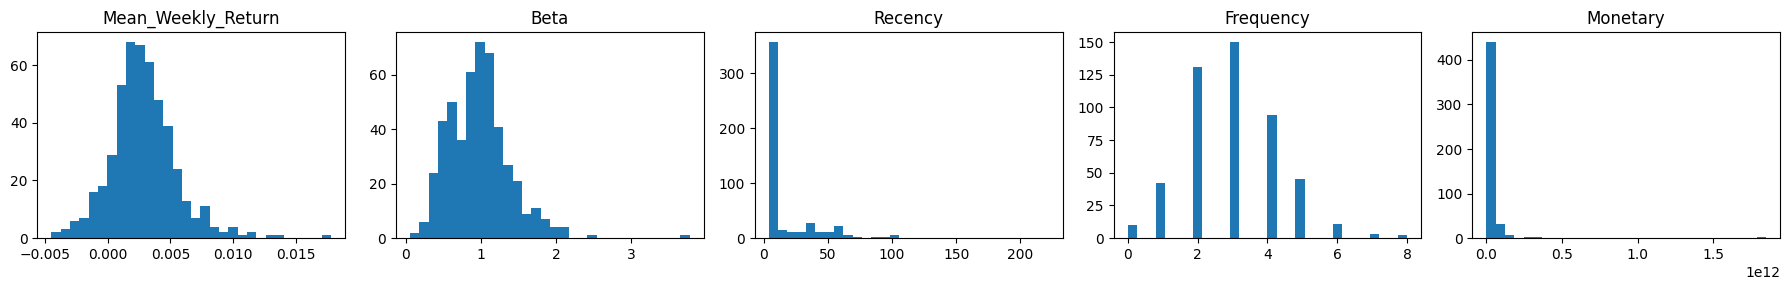


Skew after log1p(Monetary):
Recency      3.65
Frequency    0.43
Monetary     1.08
dtype: float64

Scaled means: [ 0. -0.] [-0. -0. -0.]
Scaled std: [1. 1.] [1. 1. 1.]


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

rfm = pd.read_csv("SP500_RFM_2021_2024.csv")

cluster_data = rfm.set_index("Share").copy()
cluster_data["Recency"] = cluster_data["Recency"].astype(float)

features_rr = ["Mean_Weekly_Return", "Beta"]
features_rfm = ["Recency", "Frequency", "Monetary"]

cluster_data = cluster_data.dropna(subset=features_rr + features_rfm).copy()
print("Common share set:", len(cluster_data))

print("\nSkew:")
print(cluster_data[features_rr + features_rfm].skew().round(2))
z = (cluster_data[features_rr + features_rfm] - cluster_data[features_rr + features_rfm].mean()) / cluster_data[features_rr + features_rfm].std()
print("\nOutliers (|z| > 3):")
print((z.abs() > 3).sum())

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, col in zip(axes, features_rr + features_rfm):
    ax.hist(cluster_data[col], bins=30)
    ax.set_title(col)
plt.tight_layout()
plt.show()

X_rr = cluster_data[features_rr].copy()

X_rfm = cluster_data[features_rfm].copy()
X_rfm["Monetary"] = np.log1p(X_rfm["Monetary"])
print("\nSkew after log1p(Monetary):")
print(X_rfm.skew().round(2))

X_rr_scaled = StandardScaler().fit_transform(X_rr)
X_rfm_scaled = StandardScaler().fit_transform(X_rfm)

print("\nScaled means:", X_rr_scaled.mean(axis=0).round(2), X_rfm_scaled.mean(axis=0).round(2))
print("Scaled std:", X_rr_scaled.std(axis=0).round(2), X_rfm_scaled.std(axis=0).round(2))

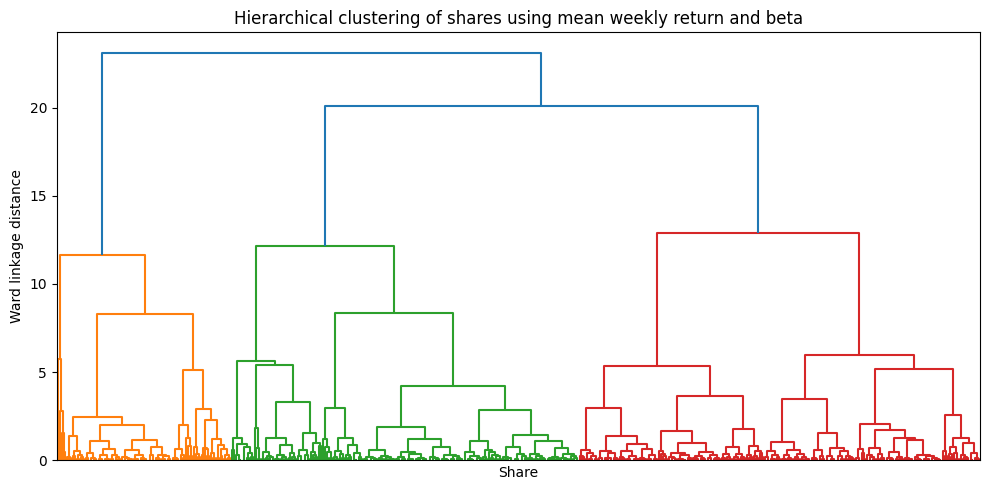

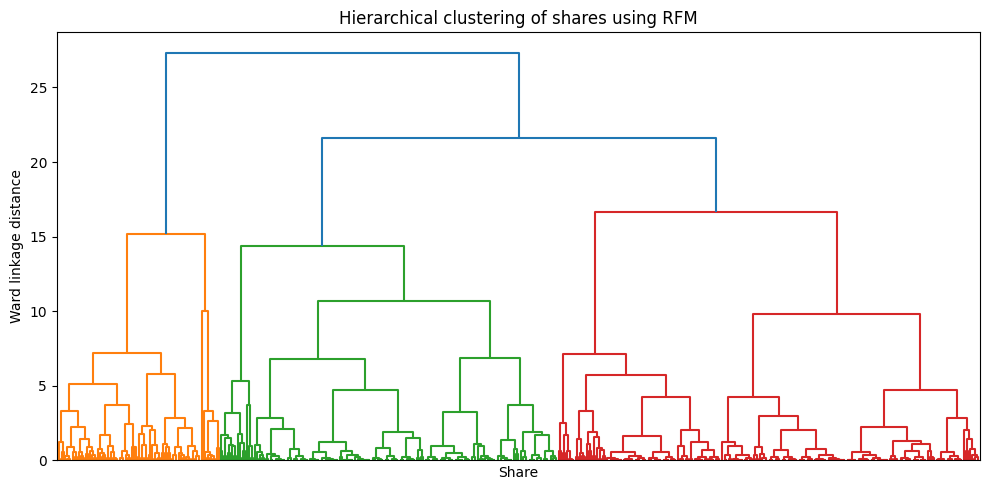

,RR_silhouette,RR_sizes,RFM_silhouette,RFM_sizes
k,,,,
2,0.340,"[396, 92]",0.369,"[402, 86]"
3,0.293,"[212, 184, 92]",0.261,"[223, 179, 86]"
4,0.265,"[184, 114, 98, 92]",0.251,"[179, 137, 86, 86]"
5,0.287,"[136, 114, 98, 92, 48]",0.270,"[179, 137, 86, 76, 10]"
6,0.304,"[136, 114, 98, 87, 48, 5]",0.291,"[161, 137, 86, 76, 18, 10]"
7,0.306,"[114, 114, 98, 87, 48, 22, 5]",0.280,"[137, 90, 86, 76, 71, 18, 10]"
8,0.314,"[114, 114, 98, 56, 48, 31, 22, 5]",0.282,"[137, 90, 86, 76, 71, 18, 9, 1]"


In [20]:
hierarchy_rr = linkage(X_rr_scaled, method="ward")
hierarchy_rfm = linkage(X_rfm_scaled, method="ward")

for hierarchy, title in [(hierarchy_rr, "mean weekly return and beta"),
                         (hierarchy_rfm, "RFM")]:
    plt.figure(figsize=(10, 5))
    dendrogram(hierarchy, no_labels=True)
    plt.title(f"Hierarchical clustering of shares using {title}")
    plt.xlabel("Share")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.show()

ward_results = []
for k in range(2, 9):
    labels_rr = cut_tree(hierarchy_rr, n_clusters=k).ravel()
    labels_rfm = cut_tree(hierarchy_rfm, n_clusters=k).ravel()
    ward_results.append({
        "k": k,
        "RR_silhouette": round(silhouette_score(X_rr_scaled, labels_rr), 3),
        "RR_sizes": sorted(np.bincount(labels_rr).tolist(), reverse=True),
        "RFM_silhouette": round(silhouette_score(X_rfm_scaled, labels_rfm), 3),
        "RFM_sizes": sorted(np.bincount(labels_rfm).tolist(), reverse=True),
    })
ward_results = pd.DataFrame(ward_results).set_index("k")
ward_results

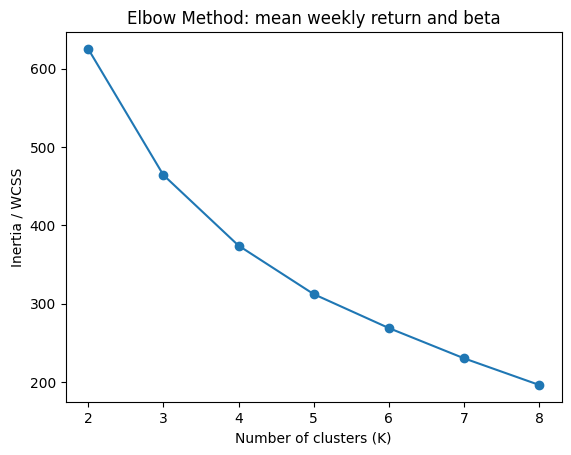

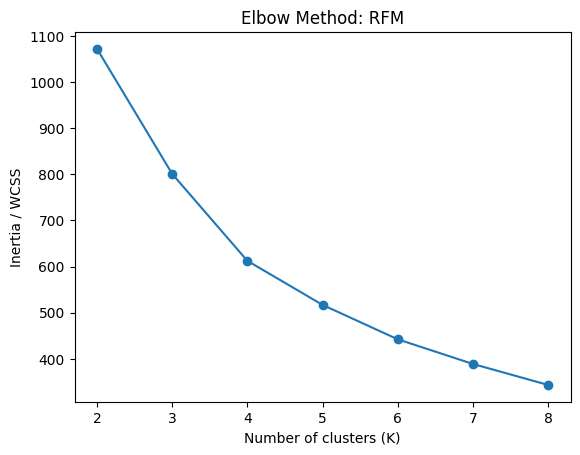

,RR_silhouette,RR_inertia,RR_sizes,RFM_silhouette,RFM_inertia,RFM_sizes
k,,,,,,
2,0.387,625.0,"[345, 143]",0.424,1071.6,"[420, 68]"
3,0.328,464.1,"[203, 166, 119]",0.325,800.7,"[273, 151, 64]"
4,0.325,374.0,"[167, 146, 133, 42]",0.341,612.5,"[213, 122, 92, 61]"
5,0.338,312.0,"[158, 128, 109, 56, 37]",0.358,517.1,"[200, 122, 87, 68, 11]"
6,0.340,268.7,"[147, 122, 105, 51, 43, 20]",0.352,442.5,"[151, 117, 104, 68, 37, 11]"
7,0.357,230.1,"[147, 87, 80, 76, 47, 41, 10]",0.341,389.1,"[138, 120, 104, 68, 46, 11, 1]"
8,0.353,196.1,"[144, 84, 77, 72, 43, 32, 31, 5]",0.343,343.7,"[151, 105, 89, 65, 49, 17, 11, 1]"


In [21]:
inertia_rr, inertia_rfm = {}, {}
kmeans_results = []

for k in range(2, 9):
    kmeans_rr = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_rr.fit(X_rr_scaled)
    inertia_rr[k] = kmeans_rr.inertia_

    kmeans_rfm = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_rfm.fit(X_rfm_scaled)
    inertia_rfm[k] = kmeans_rfm.inertia_

    kmeans_results.append({
        "k": k,
        "RR_silhouette": round(silhouette_score(X_rr_scaled, kmeans_rr.labels_), 3),
        "RR_inertia": round(kmeans_rr.inertia_, 1),
        "RR_sizes": sorted(np.bincount(kmeans_rr.labels_).tolist(), reverse=True),
        "RFM_silhouette": round(silhouette_score(X_rfm_scaled, kmeans_rfm.labels_), 3),
        "RFM_inertia": round(kmeans_rfm.inertia_, 1),
        "RFM_sizes": sorted(np.bincount(kmeans_rfm.labels_).tolist(), reverse=True),
    })
kmeans_results = pd.DataFrame(kmeans_results).set_index("k")

for inertia, title in [(inertia_rr, "mean weekly return and beta"), (inertia_rfm, "RFM")]:
    plt.plot(list(inertia.keys()), list(inertia.values()), marker="o")
    plt.xlabel("Number of clusters (K)")
    plt.ylabel("Inertia / WCSS")
    plt.title(f"Elbow Method: {title}")
    plt.show()

kmeans_results

In [22]:
K_RR_WARD = 3
K_RR_KMEANS = 3
K_RFM_WARD = 3
K_RFM_KMEANS = 3

cluster_data["RR_Ward"] = cut_tree(hierarchy_rr, n_clusters=K_RR_WARD).ravel() + 1
cluster_data["RFM_Ward"] = cut_tree(hierarchy_rfm, n_clusters=K_RFM_WARD).ravel() + 1

model_rr = KMeans(n_clusters=K_RR_KMEANS, random_state=42, n_init=10)
model_rr.fit(X_rr_scaled)
cluster_data["RR_KMeans"] = model_rr.labels_ + 1

model_rfm = KMeans(n_clusters=K_RFM_KMEANS, random_state=42, n_init=10)
model_rfm.fit(X_rfm_scaled)
cluster_data["RFM_KMeans"] = model_rfm.labels_ + 1

cluster_data.to_csv("SP500_cluster_assignments.csv")
cluster_data[["Sector"] + features_rr + features_rfm + ["RR_Ward", "RR_KMeans", "RFM_Ward", "RFM_KMeans"]].head()

,Sector,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary,RR_Ward,RR_KMeans,RFM_Ward,RFM_KMeans
Share,,,,,,,,,,
AMZN,Consumer Discretionary,0.002681,1.386667,11.0,5,4.681770e+11,1,3,1,1
AVGO,Information Technology,0.010133,1.515254,11.0,6,3.340388e+11,2,1,1,1
PLTR,Information Technology,0.009613,2.003194,11.0,6,2.869115e+11,2,1,1,1
GOOG,Communication Services,0.004629,1.209199,11.0,5,2.028245e+11,2,1,1,1
BA,Industrials,0.000614,1.134751,11.0,5,1.276863e+11,1,3,1,1


In [23]:
for cluster_col in ["RR_Ward", "RR_KMeans"]:
    cluster_profile = cluster_data.groupby(cluster_col).agg({
        "Mean_Weekly_Return": "mean",
        "Beta": ["mean", "count"]
    }).round(4)
    print(f"\n{cluster_col}:")
    print(cluster_profile)

for cluster_col in ["RFM_Ward", "RFM_KMeans"]:
    cluster_profile = cluster_data.groupby(cluster_col).agg({
        "Recency": "mean",
        "Frequency": "mean",
        "Monetary": ["mean", "count"]
    }).round(2)
    print(f"\n{cluster_col}:")
    print(cluster_profile)

for cluster_col in ["RR_Ward", "RR_KMeans", "RFM_Ward", "RFM_KMeans"]:
    print(f"\n{cluster_col} sector composition (%):")
    print((pd.crosstab(cluster_data[cluster_col], cluster_data["Sector"], normalize="index") * 100).round(1))


RR_Ward:
        Mean_Weekly_Return    Beta      
                      mean    mean count
RR_Ward                                 
1                   0.0015  1.1998   184
2                   0.0063  1.2981    92
3                   0.0025  0.6371   212

RR_KMeans:
          Mean_Weekly_Return    Beta      
                        mean    mean count
RR_KMeans                                 
1                     0.0060  1.3264   119
2                     0.0026  0.6323   203
3                     0.0010  1.1389   166

RFM_Ward:
         Recency Frequency      Monetary      
            mean      mean          mean count
RFM_Ward                                      
1          12.15      2.94  7.024891e+10   179
2          12.89      3.42  1.101312e+10   223
3          57.00      1.98  4.824805e+10    86

RFM_KMeans:
           Recency Frequency      Monetary      
              mean      mean          mean count
RFM_KMeans                                      
1            14.25   

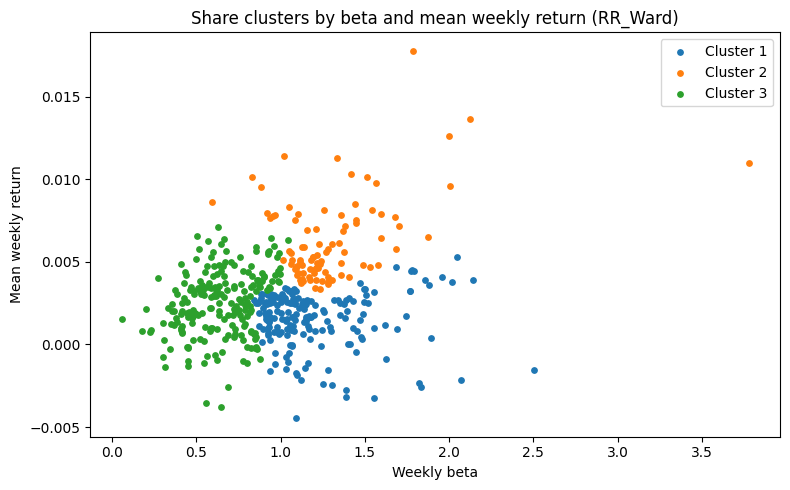

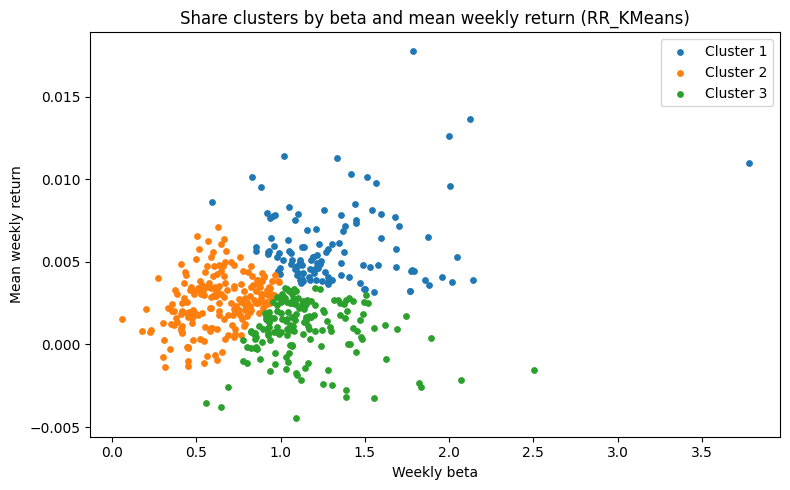

PCA explained variance: [0.458 0.336] | total: 0.794
     Recency  Frequency  Monetary
PC1    0.711     -0.650     0.269
PC2    0.023      0.403     0.915


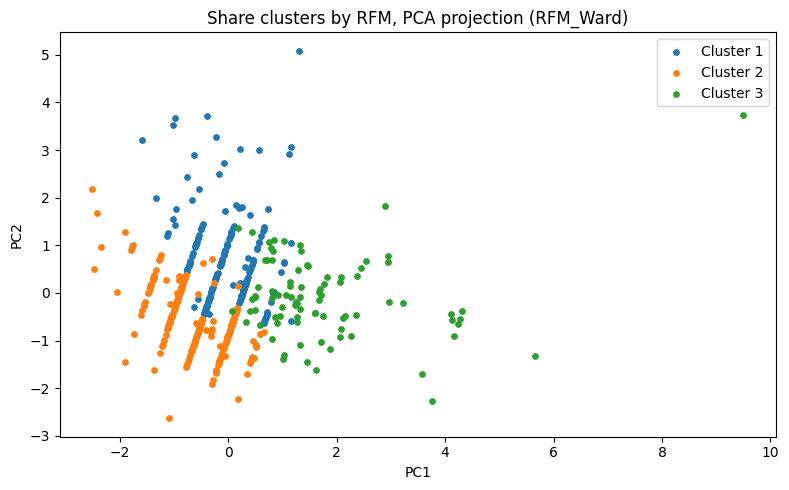

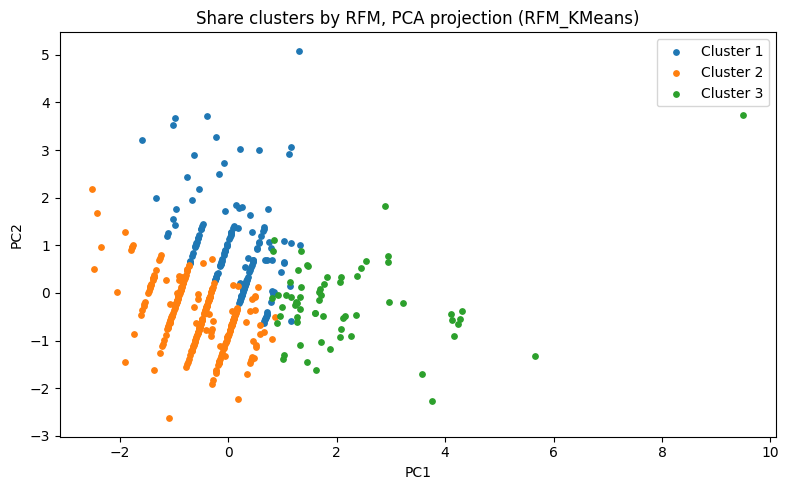

In [24]:
for cluster_col in ["RR_Ward", "RR_KMeans"]:
    plt.figure(figsize=(8, 5))
    for cluster, group in cluster_data.groupby(cluster_col):
        plt.scatter(group["Beta"], group["Mean_Weekly_Return"], s=15, label=f"Cluster {cluster}")
    plt.xlabel("Weekly beta")
    plt.ylabel("Mean weekly return")
    plt.title(f"Share clusters by beta and mean weekly return ({cluster_col})")
    plt.legend()
    plt.tight_layout()
    plt.show()

pca = PCA(n_components=2, random_state=42)
rfm_2d = pca.fit_transform(X_rfm_scaled)
cluster_data["PC1"], cluster_data["PC2"] = rfm_2d[:, 0], rfm_2d[:, 1]
print("PCA explained variance:", pca.explained_variance_ratio_.round(3), "| total:", round(pca.explained_variance_ratio_.sum(), 3))
print(pd.DataFrame(pca.components_, columns=features_rfm, index=["PC1", "PC2"]).round(3))

for cluster_col in ["RFM_Ward", "RFM_KMeans"]:
    plt.figure(figsize=(8, 5))
    for cluster, group in cluster_data.groupby(cluster_col):
        plt.scatter(group["PC1"], group["PC2"], s=15, label=f"Cluster {cluster}")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"Share clusters by RFM, PCA projection ({cluster_col})")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [25]:
print("ARI, Ward vs K-means (risk and return):", round(adjusted_rand_score(cluster_data["RR_Ward"], cluster_data["RR_KMeans"]), 3))
print("ARI, Ward vs K-means (RFM):", round(adjusted_rand_score(cluster_data["RFM_Ward"], cluster_data["RFM_KMeans"]), 3))
print("ARI, risk and return Ward vs RFM Ward:", round(adjusted_rand_score(cluster_data["RR_Ward"], cluster_data["RFM_Ward"]), 3))

print(pd.crosstab(cluster_data["RR_Ward"], cluster_data["RR_KMeans"]))
print(pd.crosstab(cluster_data["RFM_Ward"], cluster_data["RFM_KMeans"]))

ARI, Ward vs K-means (risk and return): 0.602
ARI, Ward vs K-means (RFM): 0.648
ARI, risk and return Ward vs RFM Ward: 0.01
RR_KMeans   1    2    3
RR_Ward                
1          16   22  146
2          90    0    2
3          13  181   18
RFM_KMeans    1    2   3
RFM_Ward                
1           140   39   0
2             0  223   0
3            11   11  64


In [26]:
features = cluster_data[["Recency", "Frequency", "Monetary"]].copy()

features["LogMonetary"] = np.log1p(features["Monetary"])

print("Correlations among the clustering inputs:")
print(
    features[["Recency", "Frequency", "LogMonetary"]]
    .corr()
    .round(2)
)

Correlations among the clustering inputs:
             Recency  Frequency  LogMonetary
Recency         1.00      -0.35         0.15
Frequency      -0.35       1.00         0.01
LogMonetary     0.15       0.01         1.00


In [27]:
X_rf_scaled = StandardScaler().fit_transform(cluster_data[["Recency", "Frequency"]])
hierarchy_rf = linkage(X_rf_scaled, method="ward")
cluster_data["RF_Ward"] = cut_tree(hierarchy_rf, n_clusters=K_RFM_WARD).ravel() + 1

print("Shares:", len(cluster_data), "| clusters:", K_RFM_WARD)
print("ARI, RFM Ward vs RF Ward:", round(adjusted_rand_score(cluster_data["RFM_Ward"], cluster_data["RF_Ward"]), 3))
print(pd.crosstab(cluster_data["RFM_Ward"], cluster_data["RF_Ward"]))

for cluster_col in ["RFM_Ward", "RF_Ward"]:
    cluster_profile = cluster_data.groupby(cluster_col).agg({
        "Recency": "mean",
        "Frequency": "mean",
        "Monetary": ["mean", "median", "count"]
    }).round(2)
    print(f"\n{cluster_col} traded value profile:")
    print(cluster_profile)

cluster_data.to_csv("SP500_cluster_assignments.csv")

Shares: 488 | clusters: 3
ARI, RFM Ward vs RF Ward: 0.268
RF_Ward     1   2   3
RFM_Ward             
1         119  59   1
2         152  66   5
3           2   0  84

RFM_Ward traded value profile:
         Recency Frequency      Monetary                    
            mean      mean          mean        median count
RFM_Ward                                                    
1          12.15      2.94  7.024891e+10  3.432146e+10   179
2          12.89      3.42  1.101312e+10  1.013983e+10   223
3          57.00      1.98  4.824805e+10  2.145008e+10    86

RF_Ward traded value profile:
        Recency Frequency      Monetary                    
           mean      mean          mean        median count
RF_Ward                                                    
1         12.88      3.85  3.929740e+10  1.478438e+10   273
2         11.04      1.80  3.433790e+10  1.769899e+10   125
3         56.17      2.01  4.621541e+10  2.048974e+10    90
